Found 55843 files belonging to 10 classes.
Found 9684 files belonging to 10 classes.

--- Dataset Information ---
Found 55843 training files.
Found 9684 testing files.
Class names: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

--- Inspecting One Batch ---
Images batch shape: (32, 28, 28, 1)
Labels batch shape: (32,)


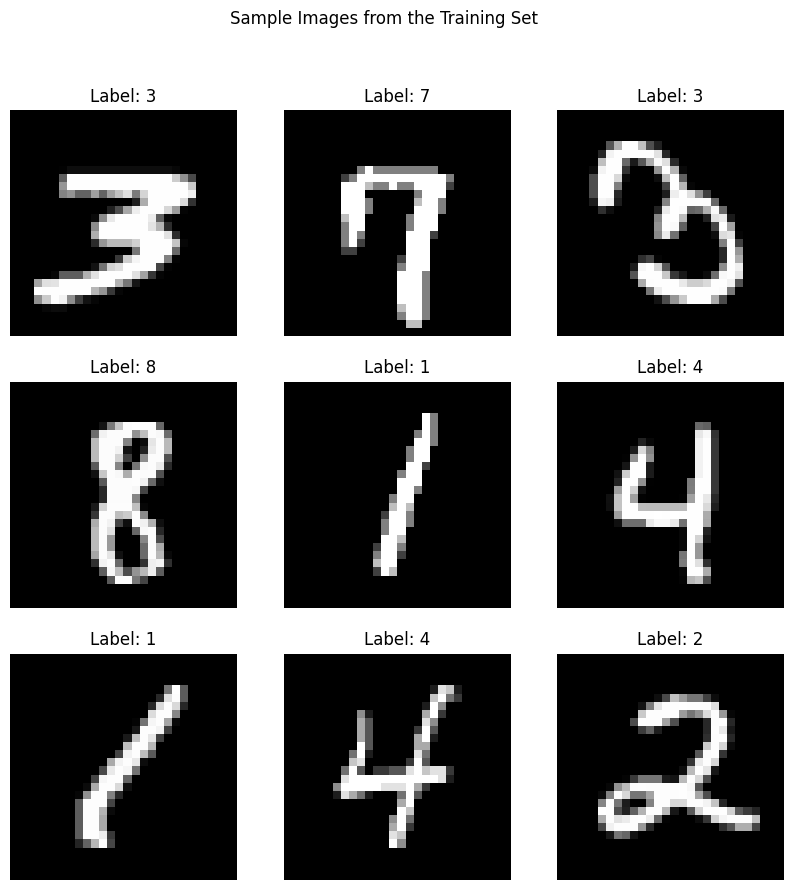

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)


--- Starting Model Training ---
Epoch 1/5
1746/1746 ━━━━━━━━━━━━━━━━━━━━ 58s 33ms/step - accuracy: 0.8997 - loss: 0.3352 - val_accuracy: 0.9785 - val_loss: 0.0707
Epoch 2/5
1746/1746 ━━━━━━━━━━━━━━━━━━━━ 27s 15ms/step - accuracy: 0.9828 - loss: 0.0531 - val_accuracy: 0.9822 - val_loss: 0.0578
Epoch 3/5
1746/1746 ━━━━━━━━━━━━━━━━━━━━ 28s 16ms/step - accuracy: 0.9881 - loss: 0.0366 - val_accuracy: 0.9850 - val_loss: 0.0478
Epoch 4/5
1746/1746 ━━━━━━━━━━━━━━━━━━━━ 27s 15ms/step - accuracy: 0.9921 - loss: 0.0249 - val_accuracy: 0.9874 - val_loss: 0.0422
Epoch 5/5
1746/1746 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.9940 - loss: 0.0193 - val_accuracy: 0.9846 - val_loss: 0.0586

--- Evaluating Model on Test Data ---
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9841 - loss: 0.0539

Test Accuracy: 98.46%


In [12]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Setup Paths and Parameters ---

# Replace with the actual path where you downloaded the data.
data_path = 'mnist-pngs-main/' 
train_path = data_path + 'train'
test_path = data_path + 'test'

# Define image and batch parameters
BATCH_SIZE = 32
IMG_HEIGHT = 28
IMG_WIDTH = 28

# --- 2. Load the Datasets ---

# Use `image_dataset_from_directory` to load the data
# - labels='inferred': Automatically get labels from folder names.
# - label_mode='int': Labels will be integers (0, 1, 2...).
# - color_mode='grayscale': Load images as single-channel grayscale.
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels='inferred',
    label_mode='int',
    color_mode='grayscale',
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_path,
    labels='inferred',
    label_mode='int',
    color_mode='grayscale',
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

print("\n--- Dataset Information ---")
print(f"Found {len(train_dataset.file_paths)} training files.")
print(f"Found {len(test_dataset.file_paths)} testing files.")
class_names = train_dataset.class_names
print(f"Class names: {class_names}")

# --- 3. Inspect and Visualize the Data ---

print("\n--- Inspecting One Batch ---")
for images, labels in train_dataset.take(1):  # Take one batch from the dataset
    print(f"Images batch shape: {images.shape}") # (batch_size, height, width, channels)
    print(f"Labels batch shape: {labels.shape}") # (batch_size,)
    
    # Let's visualize a few images from this batch
    plt.figure(figsize=(10, 10))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"), cmap='gray')
        plt.title(f"Label: {class_names[labels[i]]}")
        plt.axis("off")
    plt.suptitle("Sample Images from the Training Set")
    plt.show()


# --- 4. Prepare the Dataset for Training ---

# Normalize pixel values from [0, 255] to [0, 1]. This is crucial for model performance.
def normalize(image, label):
    return tf.cast(image, tf.float32) / 255.0, label

train_dataset = train_dataset.map(normalize)
test_dataset = test_dataset.map(normalize)

# Optimize performance with caching and prefetching
# .cache() keeps data in memory after the first epoch
# .prefetch() overlaps data preprocessing and model execution
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)


# --- 5. Build and Train a Simple CNN Model ---

model = tf.keras.Sequential([
    # Input layer with the correct shape
    tf.keras.layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 1)),
    
    # Convolutional layers
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    
    # Flatten and Dense layers for classification
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax') # 10 classes for digits 0-9
])

# Compile the model
# Use SparseCategoricalCrossentropy because labels are integers, not one-hot encoded.
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

model.summary()

# Train the model
print("\n--- Starting Model Training ---")
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=5  # Train for 5 epochs for a quick demonstration
)

# --- 6. Evaluate the Model ---
print("\n--- Evaluating Model on Test Data ---")
loss, accuracy = model.evaluate(test_dataset)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

In [13]:
# Get a batch of test images and labels
for test_images, test_labels in test_dataset.take(1):
    predictions = model.predict(test_images)
    predicted_classes = np.argmax(predictions, axis=1)
    print("Predicted classes:", predicted_classes)
    print("True labels:", test_labels.numpy())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
Predicted classes: [6 0 7 3 8 2 8 8 0 9 4 0 6 4 6 8 4 6 0 3 1 6 7 3 1 6 6 0 3 4 3 2]
True labels: [6 0 7 3 8 2 8 2 0 9 4 0 6 4 6 8 4 6 0 3 1 6 7 3 1 6 6 0 3 4 3 2]


In [37]:
my_test_path = data_path + 'my_test'

# Load images from the my_test folder without labels
my_test_dataset = tf.keras.utils.image_dataset_from_directory(
    my_test_path,
    labels=None,
    color_mode='grayscale',
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

# Normalize the images
my_test_dataset = my_test_dataset.map(lambda x: tf.cast(x, tf.float32) / 255.0)

# Predict on the images in my_test
for images in my_test_dataset:
    predictions = model.predict(images)
    predicted_classes = np.argmax(predictions, axis=1)
    print("Predicted classes:", predicted_classes)
    #break  # Remove this break if you want to process all batches


Found 7 files.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Predicted classes: [9 4 3 5 1 1 5]


In [ ]:
# ...existing code...

# After training the model
model.save('mnist_model.h5')
print("Model saved as mnist_model.h5")
# ...existing code...

In [ ]:
import gradio as gr
import numpy as np
from PIL import Image
import tensorflow as tf
import os

IMG_HEIGHT = 28
IMG_WIDTH = 28

# Load the trained model
model_path = "mnist_model.h5"
model = tf.keras.models.load_model(model_path)

def predict_digit(image):
    # Convert to grayscale, resize, normalize, and reshape
    image = image.convert('L').resize((IMG_WIDTH, IMG_HEIGHT))
    img_array = np.array(image).astype('float32') / 255.0
    img_array = img_array.reshape(1, IMG_HEIGHT, IMG_WIDTH, 1)
    prediction = model.predict(img_array)
    predicted_class = np.argmax(prediction, axis=1)[0]
    confidence = np.max(prediction)
    return f"Predicted Digit: {predicted_class} (Confidence: {confidence:.2f})"

demo = gr.Interface(
    fn=predict_digit,
    inputs=gr.Image(type="pil", label="Upload a digit image"),
    outputs=gr.Textbox(label="Prediction"),
    title="MNIST Digit Classifier",
    description="Upload a 28x28 grayscale image of a digit (0-9) to get a prediction."
)

if __name__ == "__main__":
    demo.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step
